## Training a U-Net from scratch

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # PyTorch for GPU

Choose the label level and build a lookup table

In [2]:
import json
import pathlib

import numpy as np
from PIL import Image

Image.MAX_IMAGE_PIXELS = None
base_dir = pathlib.Path("bcss_split")
granularity = "five"  # "binary", "five" or "fine"

with open(base_dir / "class_groupings.json") as f:
    groupings = json.load(f)["groupings"]
class_names = list(groupings[granularity])
num_classes = len(class_names)
ignore_index = 255

lookup = np.full(256, ignore_index, dtype="uint8")
for index, codes in enumerate(groupings[granularity].values()):
    lookup[codes] = index
is_tumor = np.array([1 in codes for codes in groupings[granularity].values()])
print(class_names, is_tumor)

['tumor', 'stroma', 'inflammatory', 'necrosis', 'other'] [ True False False False False]


## Cutting the regions into tiles

In [3]:
tile_size = 512

def load_tiles(subset, min_labelled=0.5):
    images, targets = [], []
    for path in sorted((base_dir / subset / "images").glob("*.png")):
        img = np.asarray(Image.open(path).convert("RGB"))
        target = lookup[np.asarray(Image.open(base_dir / subset / "masks" / path.name))]
        h, w = target.shape
        for y in range(0, h - tile_size + 1, tile_size):
            for x in range(0, w - tile_size + 1, tile_size):
                tile_target = target[y:y + tile_size, x:x + tile_size]
                if (tile_target != ignore_index).mean() >= min_labelled:
                    images.append(img[y:y + tile_size, x:x + tile_size])
                    targets.append(tile_target)
    return np.stack(images), np.stack(targets)

train_images, train_targets = load_tiles("train")
val_images, val_targets = load_tiles("validation")
print(train_images.shape, train_targets.shape, val_images.shape, val_targets.shape)

(1386, 512, 512, 3) (1386, 512, 512) (256, 512, 512, 3) (256, 512, 512)


## Data augmentation

In [4]:
import keras

class TileDataset(keras.utils.PyDataset):
    def __init__(self, images, targets, batch_size, augment=False, **kwargs):
        super().__init__(**kwargs)
        self.images, self.targets = images, targets
        self.batch_size, self.augment = batch_size, augment
        self.order = np.arange(len(images))
        self.rng = np.random.default_rng(1337)
        if augment:
            self.rng.shuffle(self.order)

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, index):
        batch = self.order[index * self.batch_size:(index + 1) * self.batch_size]
        x, y = self.images[batch].copy(), self.targets[batch].copy()
        if self.augment:
            # the same random rotation and flip for image and mask: tissue has no "up"
            for i in range(len(x)):
                k = self.rng.integers(4)
                x[i], y[i] = np.rot90(x[i], k), np.rot90(y[i], k)
                if self.rng.random() < 0.5:
                    x[i], y[i] = np.fliplr(x[i]), np.fliplr(y[i])
        return x.astype("float32"), y.astype("int32")

    def on_epoch_end(self):
        if self.augment:
            self.rng.shuffle(self.order)

batch_size = 4
train_dataset = TileDataset(train_images, train_targets, batch_size, augment=True)
val_dataset = TileDataset(val_images, val_targets, batch_size)

## Training batch

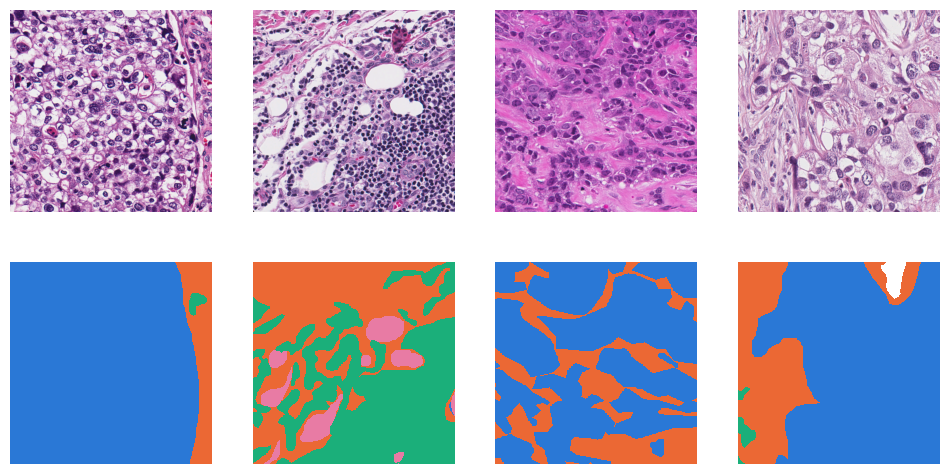

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

class_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
mask_cmap = ListedColormap(class_colors[:num_classes] + ["#ffffff"])  # white = ignored
mask_norm = BoundaryNorm(np.arange(num_classes + 2) - 0.5, mask_cmap.N)

def show_mask(ax, target):
    ax.imshow(np.where(target == ignore_index, num_classes, target),
              cmap=mask_cmap, norm=mask_norm, interpolation="nearest")
    ax.axis("off")

x, y = train_dataset[0]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(x[i].astype("uint8"))
    axes[0, i].axis("off")
    show_mask(axes[1, i], y[i])
plt.show()

## Building the U-Net

In [6]:
from keras import layers

def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x

def get_model(img_size, num_classes, base_filters=32, depth=4):
    inputs = keras.Input(shape=img_size + (3,))
    x = layers.Rescaling(1.0 / 255)(inputs)

    skips = []
    for level in range(depth):  # contracting path: learn WHAT is in the image
        x = conv_block(x, base_filters * 2**level)
        skips.append(x)
        x = layers.MaxPooling2D(2)(x)

    x = conv_block(x, base_filters * 2**depth)  # bottleneck

    for level in reversed(range(depth)):  # expanding path: decide WHERE
        x = layers.Conv2DTranspose(base_filters * 2**level, 2, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skips[level]])  # skip connection
        x = conv_block(x, base_filters * 2**level)

    outputs = layers.Conv2D(num_classes, 1, dtype="float32")(x)  # logits; the loss applies softmax
    return keras.Model(inputs, outputs)

keras.mixed_precision.set_global_policy("mixed_float16")
keras.utils.set_random_seed(1337)
model = get_model(img_size=(tile_size, tile_size), num_classes=num_classes)
print(f"{model.count_params():,} parameters")

7,769,061 parameters


## Training the model

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=ignore_index),
)
callbacks = [
    keras.callbacks.ModelCheckpoint("unet_scratch_five.keras", save_best_only=True, monitor="val_loss"),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8),
    keras.callbacks.CSVLogger("unet_scratch_five_log.csv"),
]
history = model.fit(
    train_dataset,
    epochs=40,
    validation_data=val_dataset,
    callbacks=callbacks,
)

Epoch 1/40


OutOfMemoryError: Exception encountered when calling Conv2DTranspose.call().

[1mCUDA out of memory. Tried to allocate 64.00 MiB. GPU 0 has a total capacity of 8.00 GiB of which 3.39 GiB is free. Process 1924 has 17179869184.00 GiB memory in use. Process 8488 has 17179869184.00 GiB memory in use. Process 9840 has 17179869184.00 GiB memory in use. Process 11404 has 17179869184.00 GiB memory in use. Process 11380 has 17179869184.00 GiB memory in use. Process 12264 has 17179869184.00 GiB memory in use. Process 11212 has 17179869184.00 GiB memory in use. Process 14188 has 17179869184.00 GiB memory in use. Process 15128 has 17179869184.00 GiB memory in use. Process 17020 has 17179869184.00 GiB memory in use. Process 18200 has 17179869184.00 GiB memory in use. Process 6360 has 17179869184.00 GiB memory in use. Process 19364 has 17179869184.00 GiB memory in use. Process 19600 has 17179869184.00 GiB memory in use. Process 20060 has 17179869184.00 GiB memory in use. Process 21264 has 171798691

In [ ]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, loss, color="#2a78d6", label="Training loss")
plt.plot(epochs, val_loss, color="#eb6834", label="Validation loss")
plt.title("U-Net from scratch, five classes", loc="left")
plt.xlabel("Epochs")
plt.legend(frameon=False)
plt.savefig("figures/unet_scratch_five_loss.png", dpi=200, bbox_inches="tight")
plt.show()

## Evaluating on the validation tiles

In [ ]:
import pandas as pd

def confusion_matrix(model, images, targets, batch_size=4):
    cm = np.zeros((num_classes, num_classes), dtype="int64")
    for i in range(0, len(images), batch_size):
        pred = model.predict(images[i:i + batch_size].astype("float32"), verbose=0).argmax(-1)
        true = targets[i:i + batch_size]
        labelled = true != ignore_index
        cm += np.bincount(true[labelled].astype("int64") * num_classes + pred[labelled],
                          minlength=num_classes**2).reshape(num_classes, num_classes)
    return cm  # rows = true class, columns = predicted class

def dice_scores(cm):
    tp = np.diag(cm)
    return 2 * tp / np.maximum(cm.sum(0) + cm.sum(1), 1)

def tumor_dice(cm):
    t = is_tumor
    tp, fn, fp = cm[np.ix_(t, t)].sum(), cm[np.ix_(t, ~t)].sum(), cm[np.ix_(~t, t)].sum()
    return 2 * tp / (2 * tp + fp + fn)

best_model = keras.models.load_model("unet_scratch_five.keras")
cm = confusion_matrix(best_model, val_images, val_targets)
print(pd.Series(dice_scores(cm), index=class_names).round(3))
print(f"mean Dice: {dice_scores(cm).mean():.3f} | tumour Dice: {tumor_dice(cm):.3f}")

In [ ]:
x = val_images[[0, 60, 120]]
pred = best_model.predict(x.astype("float32"), verbose=0).argmax(-1)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, i in enumerate([0, 60, 120]):
    axes[row, 0].imshow(val_images[i])
    axes[row, 0].axis("off")
    show_mask(axes[row, 1], val_targets[i])
    show_mask(axes[row, 2], pred[row])
axes[0, 0].set_title("image", loc="left")
axes[0, 1].set_title("true mask", loc="left")
axes[0, 2].set_title("prediction", loc="left")
plt.savefig("figures/unet_scratch_five_examples.png", dpi=150, bbox_inches="tight")
plt.show()